# Lesson 25 - CNNs with "other": which picture of the sound, and do the features help?

Lesson 17 trained EfficientNet-B0 on the mel spectrogram together with the engineered features, on five classes
without "other", and it was no better than gradient boosting on the same numbers. This lesson asks question 7 again
with "other" kept (6 classes + other, lesson 22), and compares the **picture** the network looks at:

| Input | Size | What it is |
|---|---|---|
| mel | 128 × 501 | the cached log-mel spectrogram, 10 Hz-16 kHz: the sound *before* MFCC |
| MFCC image | 40 × 501 | the same frames after the DCT over the bands: the sound *after* MFCC |
| linear spectrogram | 513 × 501 | computed from the audio, 1,024-sample window (31 Hz bins up to 16 kHz), no mel grouping |
| mel + features | 128 × 501 + 523 | the mel picture, and the feature sets kept by lesson 23's walk joining before the output layer |

One recipe for all four (lesson 17's): EfficientNet-B0 from ImageNet, AdamW 3e-4, SpecAugment, ship weights, the epoch
kept by validation balanced accuracy, stop after 3 epochs without improvement. **Fold 1 only**, for time: each run
takes 15-90 minutes on the laptop's RTX 3050. The fold-1 scores of the classical models are the reference; the
spread over folds was about ± 1 point per clip (lesson 22), so smaller differences are not meaningful.

```
python src/cnn_with_other.py --input mel --fold 1           # also --input mfcc, --input stft, --input mel --features
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import with_other as W

CNN = W.RUNS_DIR / "cnn_with_other"
NAMES = {"f1_mel": "CNN, mel", "f1_mfcc": "CNN, MFCC image", "f1_stft": "CNN, linear spectrogram",
         "f1_mel_features": "CNN, mel + walk features"}
runs = {k: json.loads((CNN / k / "results.json").read_text()) for k in NAMES if (CNN / k / "results.json").exists()}
logs = {k: pd.read_csv(CNN / k / "log.csv") for k in runs}
pd.set_option("display.width", 170)

## 1. Results on fold 1

In [2]:
rows = [{"model": NAMES[k], "per clip": round(100 * r["balanced_accuracy"], 1),
         "per ship": round(100 * r["per_ship_balanced_accuracy"], 1),
         "other recall": round(100 * r["per_class_recall"]["other"], 1),
         "best epoch": r["best_epoch"], "epochs run": r["epochs_run"], "minutes": r["minutes"],
         "s per epoch": round(logs[k].seconds.mean()), "predict (µs/clip)": round(r["predict_us_per_clip_with_loading"])}
        for k, r in runs.items()]
main = pd.DataFrame(W.Log(W.OUT_DIR / "main.jsonl").rows)
cost = pd.DataFrame(W.Log(W.OUT_DIR / "cost.jsonl").rows)
for frame, feats, label in ((main, "mel mean + spread (257)", "mel mean + spread"),
                            (main, "engineered + mel mean + spread (401)", "engineered + mel (401)")):
    for model in ("gradient boosting", "logistic regression"):
        r = frame[(frame.fold == 1) & (frame.features == feats) & (frame.model == model)].iloc[0]
        rows.append({"model": f"{model}, {label}", "per clip": round(100 * r.balanced_accuracy, 1),
                     "per ship": round(100 * r.per_ship_balanced_accuracy, 1),
                     "other recall": round(100 * r.per_class_recall["other"], 1),
                     "minutes": round((r.seconds_choose + r.seconds_fit) / 60, 1),
                     "predict (µs/clip)": round(r.predict_us_per_clip, 1)})
walk = json.loads((W.OUT_DIR / "walk_result.json").read_text())["final"]
r = cost[(cost.fold == 1) & (cost.features == walk) & (cost.model == "gradient boosting")].iloc[0]
rows.append({"model": "gradient boosting, walk features (523)", "per clip": round(100 * r.balanced_accuracy, 1),
             "per ship": round(100 * r.per_ship_balanced_accuracy, 1), "other recall": round(100 * r.per_class_recall["other"], 1),
             "minutes": round((r.seconds_choose + r.seconds_fit) / 60, 1), "predict (µs/clip)": round(r.predict_us_per_clip, 1)})
table = pd.DataFrame(rows).set_index("model")
print("6 classes + other, fold 1 test ships, balanced accuracy (%)  (CNN minutes on the GPU, classical on the CPU)")
print(table.to_string())

6 classes + other, fold 1 test ships, balanced accuracy (%)  (CNN minutes on the GPU, classical on the CPU)
                                             per clip  per ship  other recall  best epoch  epochs run  minutes  s per epoch  predict (µs/clip)
model                                                                                                                                         
CNN, mel                                         50.4      56.1           8.7         2.0         5.0     16.3        185.0             4005.0
CNN, MFCC image                                  49.1      54.1           6.9         3.0         6.0     10.9        102.0             3191.0
CNN, linear spectrogram                          51.1      58.7          17.1         5.0         8.0    117.2        853.0            17450.0
CNN, mel + walk features                         52.7      59.2          18.5         6.0         9.0     30.2        196.0             3499.0
gradient boosting, mel mean + spre

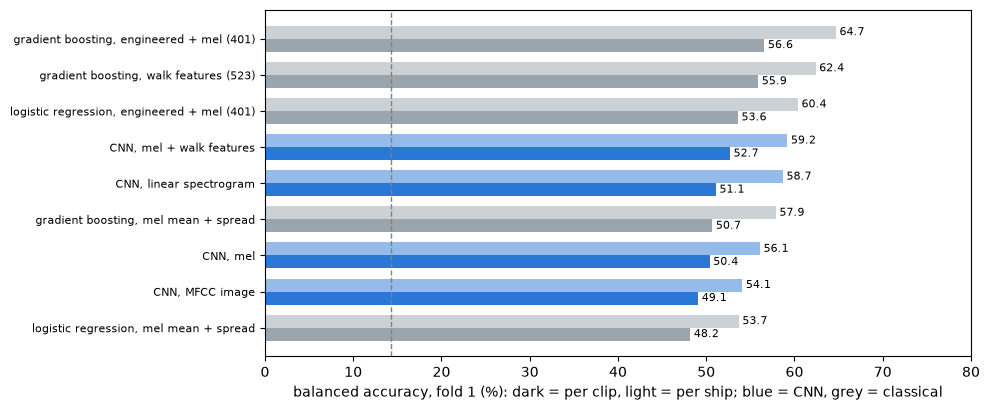

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
t = table.sort_values("per clip")
y = np.arange(len(t))
colors = ["#2a78d6" if m.startswith("CNN") else "#9aa5ad" for m in t.index]
ax.barh(y - 0.18, t["per clip"], 0.36, color=colors, label="per clip")
ax.barh(y + 0.18, t["per ship"], 0.36, color=colors, alpha=0.5, label="per ship")
for yi, (c, s_) in enumerate(zip(t["per clip"], t["per ship"])):
    ax.text(c + 0.4, yi - 0.18, f"{c:.1f}", va="center", fontsize=8)
    ax.text(s_ + 0.4, yi + 0.18, f"{s_:.1f}", va="center", fontsize=8)
ax.set_yticks(y, t.index, fontsize=8); ax.set_xlim(0, 80); ax.axvline(100 / 7, color="grey", ls="--", lw=1)
ax.set_xlabel("balanced accuracy, fold 1 (%): dark = per clip, light = per ship; blue = CNN, grey = classical")
plt.tight_layout(); plt.show()

- **The picture matters little:** mel 50.4 %, MFCC image 49.1 %, linear spectrogram 51.1 % per clip. The linear
  spectrogram is a point better than mel per ship (58.7 against 56.1 %) but takes 7 times as long to train (117
  against 16 minutes), as its picture is four times taller and is computed from the audio at every epoch.
- **The CNN does not beat gradient boosting on the same information:** on the mel spectrogram alone it ties gradient
  boosting on the 257 mel-band numbers (50.4 against 50.7 % per clip).
- **The features help the CNN, but it stays behind:** mel + the walk's 523 numbers gives 52.7 / 59.2 %, against
  55.9 / 62.4 % for gradient boosting on those 523 numbers alone and 56.6 / 64.7 % on the 401-number set.
- **The CNN hardly ever says "other"** (7-19 % recall, against 29 % for gradient boosting): with few, very different
  ships behind "other", it learns those ships rather than a class.
- Cost: a CNN run takes 11-117 minutes on the GPU and 3-17 ms per clip to predict (with loading); gradient boosting
  fits in 2-4 minutes on the CPU and predicts in 0.01-0.03 ms per clip.

## 2. Training curves

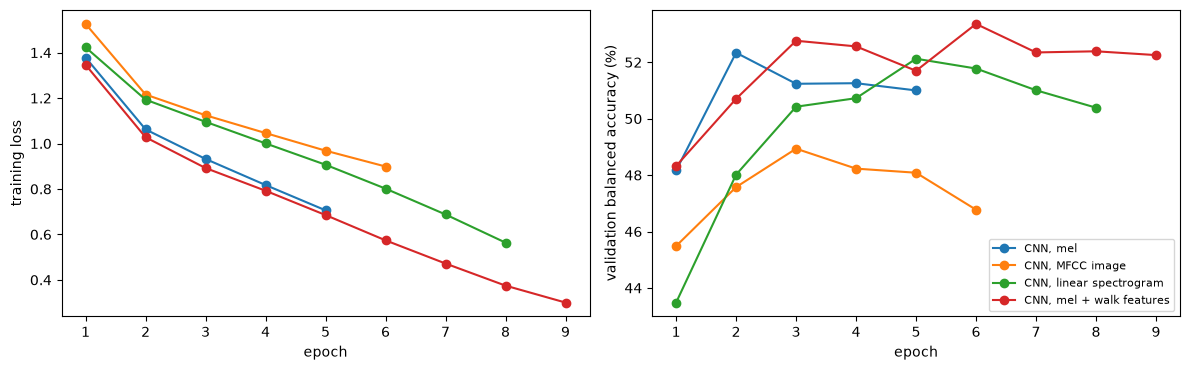

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, lg in logs.items():
    ax[0].plot(lg.epoch, lg.train_loss, marker="o", label=NAMES[k])
    ax[1].plot(lg.epoch, 100 * lg.val_balanced_accuracy, marker="o", label=NAMES[k])
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training loss"); ax[1].set_xlabel("epoch")
ax[1].set_ylabel("validation balanced accuracy (%)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

- **Every run peaks early** (best epoch 2-6 of at most 12) and then stops improving while the training loss keeps
  falling: the networks memorise the training ships, as in lessons 05 and 17. More epochs or a bigger network would
  not help; more different ships per class, or a pretrained audio model fine-tuned gently, might.

## 3. What it means

| 6 classes + other, fold 1 | Per clip | Per ship |
|---|---|---|
| CNN, best input (mel + features) | 52.7 % | 59.2 % |
| CNN, best picture alone (linear spectrogram) | 51.1 % | 58.7 % |
| **Gradient boosting, engineered + mel (401)** | **56.6 %** | **64.7 %** |

**Decision:** gradient boosting on the engineered + mel features stays the model to report. Of the pictures, keep
the mel spectrogram for any further CNN work: the linear spectrogram's one point per ship is not worth 7 times the
training time. One fold only; the fold-to-fold spread is about ± 1 point per clip.